# 00 — Data tour: what Sentinel-1 and Sentinel-2 see

Run after `scripts/01_download.py` and `scripts/02_make_labels.py`.

| | Sentinel-1 (radar) | Sentinel-2 (optical) |
|---|---|---|
| Measures | backscattered microwave energy (VV, VH), in dB | reflected sunlight per band (here green B03 and SWIR B11) |
| Clouds | sees through | blocked |
| Water looks | very dark (mirror-like) | MNDWI = (green − SWIR)/(green + SWIR) > 0 |
| Role here | **model input** | **weak labels** on clear days only |

**What we are after:** for each rice pixel and each Sentinel-1 date, *flooded or drained?* Sentinel-2 gives the answer only on some dates and some pixels; the model must learn to answer from radar alone, everywhere and always.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from ricepaddy.config import load_config
from ricepaddy.data import open_s1
from ricepaddy.labels import mndwi, match_dates, CLEAR_SCL

CONFIG = None   # None = chapter 1 (config.yaml); "../config_ch2.yaml" = both orbits
cfg = load_config(CONFIG)
s1 = open_s1(cfg)   # normalised per orbit if the config says so
s2 = xr.open_zarr(cfg["paths"]["s2"]).load()
labels = xr.open_zarr(cfg["paths"]["labels"])["label"].load()
m = mndwi(s2)
clear = s2["scl"].isin(CLEAR_SCL)
print(f"S1: {s1.sizes['time']} dates | S2: {s2.sizes['time']} dates | grid {s1.sizes['y']}x{s1.sizes['x']} px at {cfg['aoi']['resolution']} m")

S1: 17 dates | S2: 18 dates | grid 830x823 px at 20 m


## 1. Timeline: when does each satellite pass, and which radar dates get a label?
A Sentinel-1 date is labelled only if a Sentinel-2 image exists within `max_days_apart` days. Bar height = share of cloud-free pixels in the Sentinel-2 image.

11/17 radar dates labelled


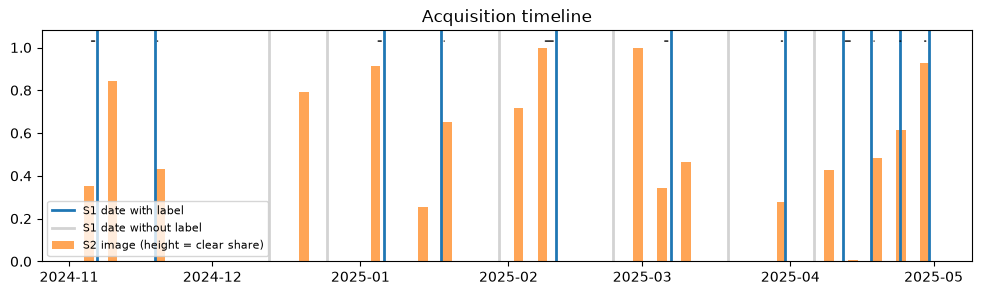

In [2]:
pairs = match_dates(s1.time.values, s2.time.values, cfg["labels"]["max_days_apart"])
clear_share = clear.mean(["y", "x"]).to_series()
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(clear_share.index, clear_share.values, width=2, color="tab:orange", alpha=.7, label="S2 image (height = clear share)")
for t in s1.time.values:
    ax.axvline(t, color="tab:blue" if pd.Timestamp(t) in pairs else "lightgray", lw=2)
for t1, t2 in pairs.items():
    ax.annotate("", xy=(t2, 1.03), xytext=(t1, 1.03), arrowprops=dict(arrowstyle="-", color="k"))
ax.plot([], [], color="tab:blue", lw=2, label="S1 date with label"); ax.plot([], [], color="lightgray", lw=2, label="S1 date without label")
ax.set_ylim(0, 1.08); ax.legend(loc="lower left", fontsize=8); ax.set_title("Acquisition timeline")
print(f"{len(pairs)}/{s1.sizes['time']} radar dates labelled")

## 2. Side by side on matched dates
For each labelled radar date: radar VH, optical MNDWI, cloud mask, and the resulting label (blue = water, brown = dry, white = unlabelled: cloud or ambiguous MNDWI).

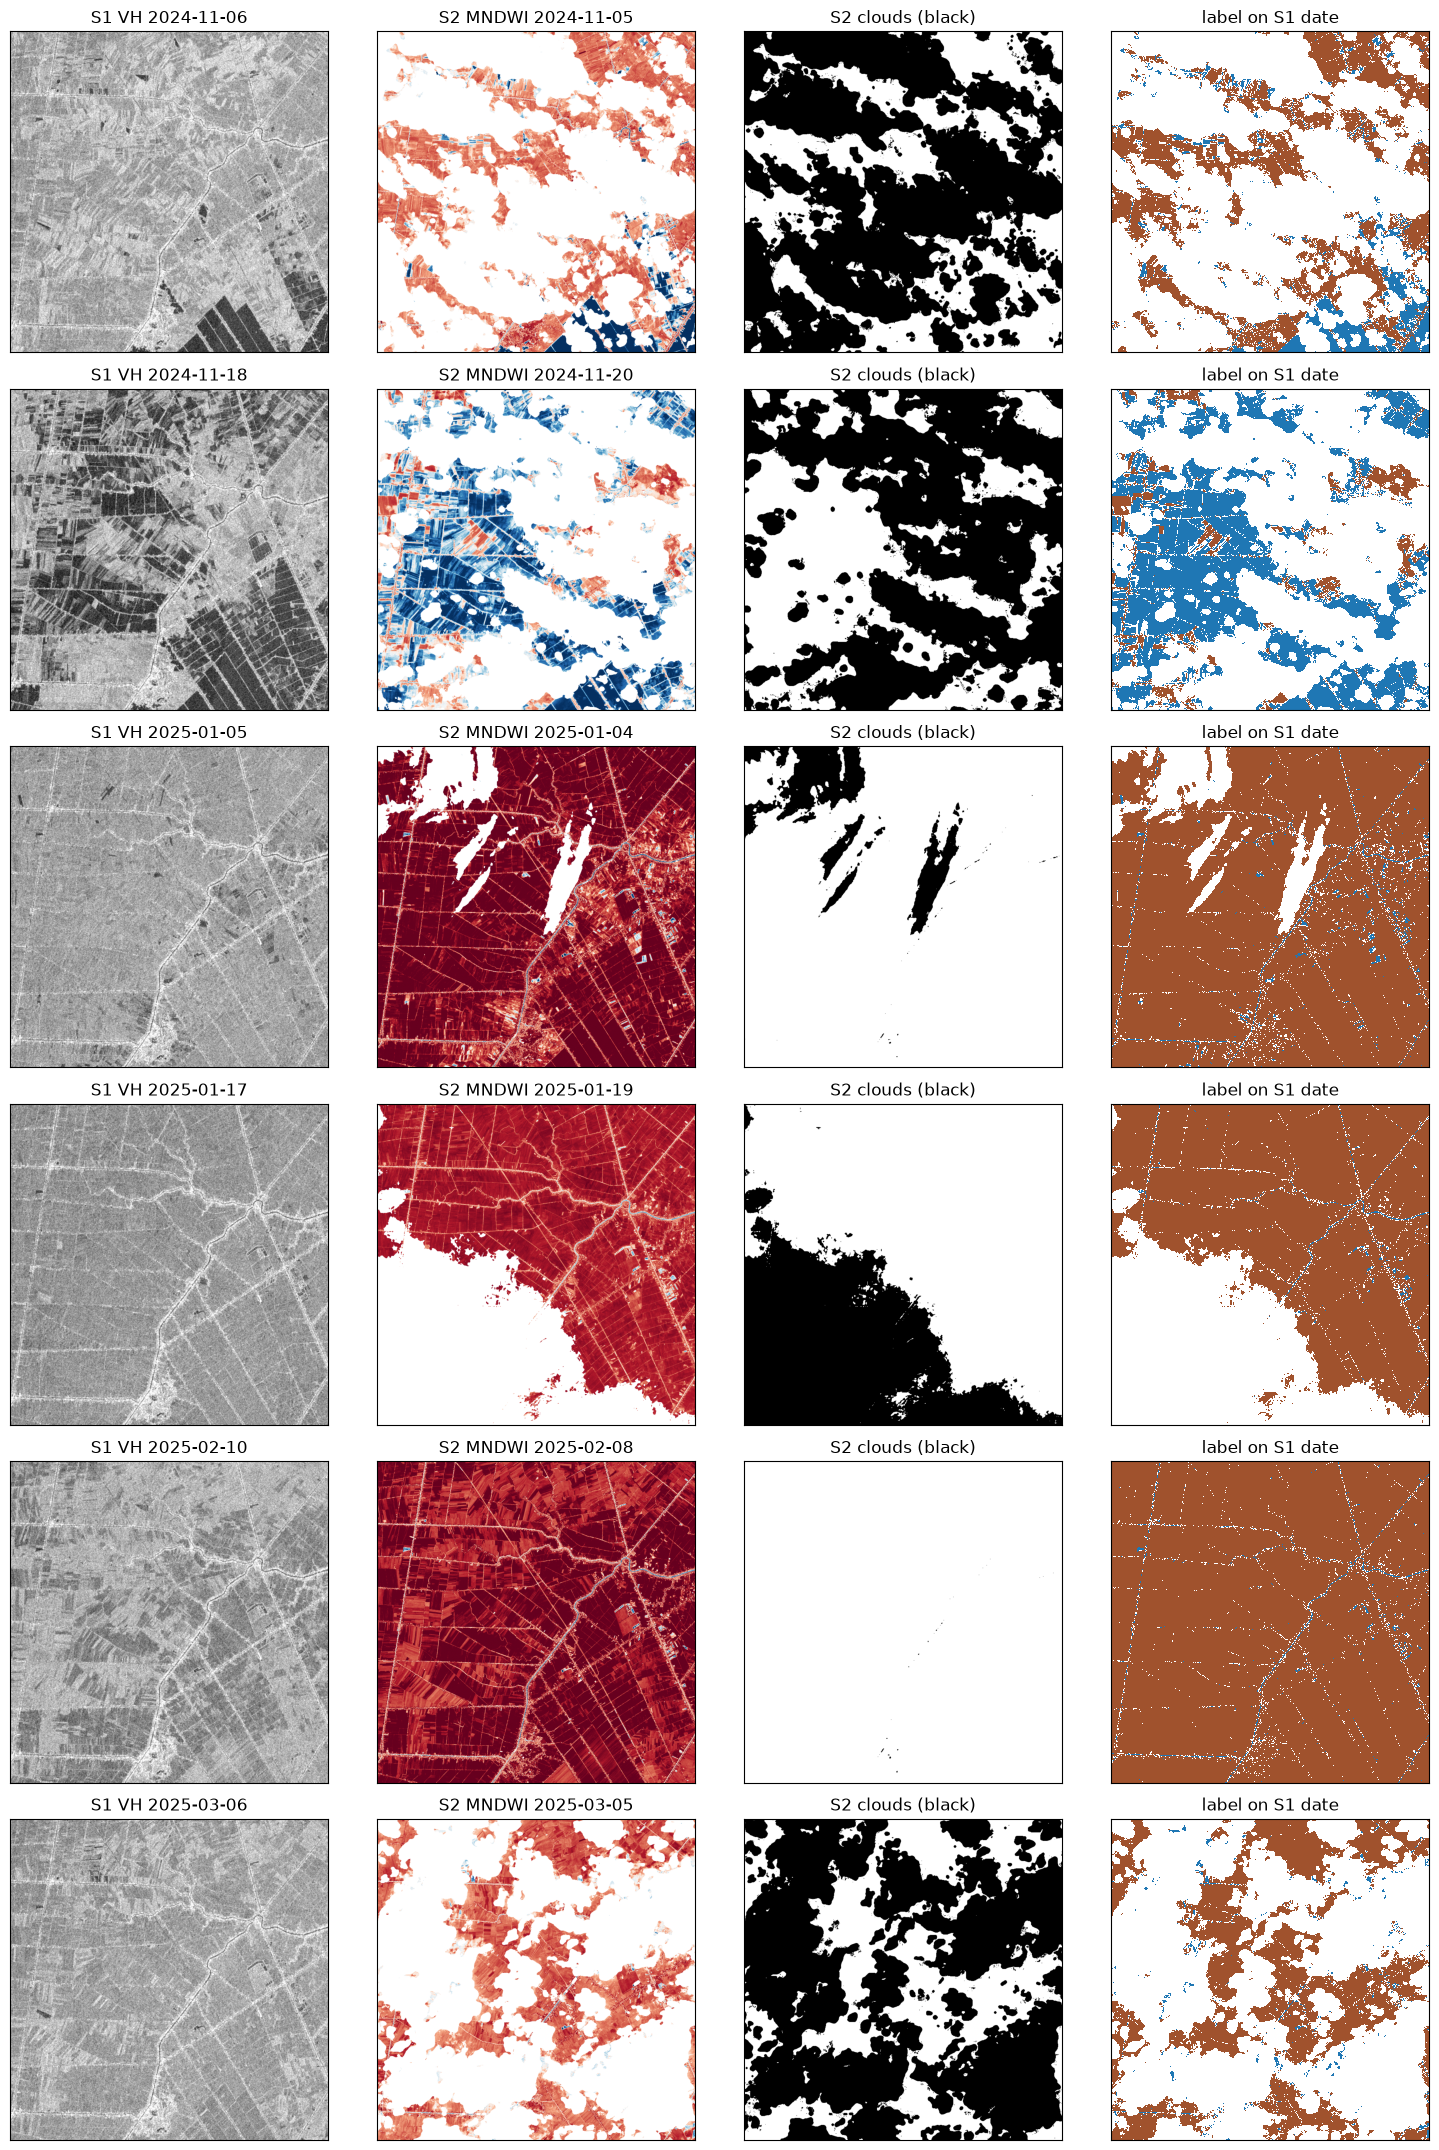

In [3]:
from matplotlib.colors import ListedColormap
lab_cmap = ListedColormap(["white", "sienna", "tab:blue"])   # -1, 0, 1
show = list(pairs.items())[:6]
fig, axs = plt.subplots(len(show), 4, figsize=(15, 3.6 * len(show)), squeeze=False)
for row, (t1, t2) in zip(axs, show):
    row[0].imshow(s1.vh_db.sel(time=t1), cmap="gray", vmin=-28, vmax=-8); row[0].set_title(f"S1 VH {str(t1)[:10]}")
    row[1].imshow(m.sel(time=t2), cmap="RdBu", vmin=-0.6, vmax=0.6); row[1].set_title(f"S2 MNDWI {str(t2)[:10]}")
    row[2].imshow(~clear.sel(time=t2), cmap="Greys", vmin=0, vmax=1); row[2].set_title("S2 clouds (black)")
    row[3].imshow(labels.sel(time=t1) + 1, cmap=lab_cmap, vmin=0, vmax=2, interpolation="nearest"); row[3].set_title("label on S1 date")
    for a in row: a.set_xticks([]); a.set_yticks([])
plt.tight_layout()

## 3. Zoom on a few fields
The full scene is 16 km wide; individual paddies are 100-300 m. Change `y0, x0` to explore.

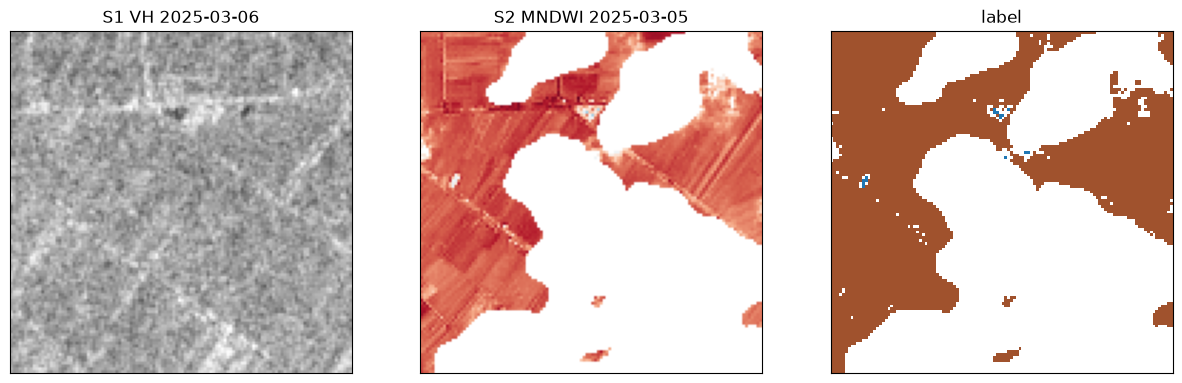

In [4]:
y0, x0, w = 300, 300, 120          # pixel window (120 px = 2.4 km)
y0, x0 = min(y0, s1.sizes['y'] - w), min(x0, s1.sizes['x'] - w)
t1, t2 = list(pairs.items())[len(pairs) // 2]
win = dict(y=slice(y0, y0 + w), x=slice(x0, x0 + w))
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(s1.vh_db.sel(time=t1).isel(**win), cmap="gray", vmin=-28, vmax=-8); axs[0].set_title(f"S1 VH {str(t1)[:10]}")
axs[1].imshow(m.sel(time=t2).isel(**win), cmap="RdBu", vmin=-0.6, vmax=0.6); axs[1].set_title(f"S2 MNDWI {str(t2)[:10]}")
axs[2].imshow(labels.sel(time=t1).isel(**win) + 1, cmap=lab_cmap, vmin=0, vmax=2, interpolation="nearest"); axs[2].set_title("label")
for a in axs: a.set_xticks([]); a.set_yticks([])

## 4. Whole season for one pixel: radar every date, optical when clear
Blue dots = MNDWI on clear days (right axis). Shaded = water label. Pick another pixel to compare.

Text(0.5, 1.0, 'pixel y=360, x=360')

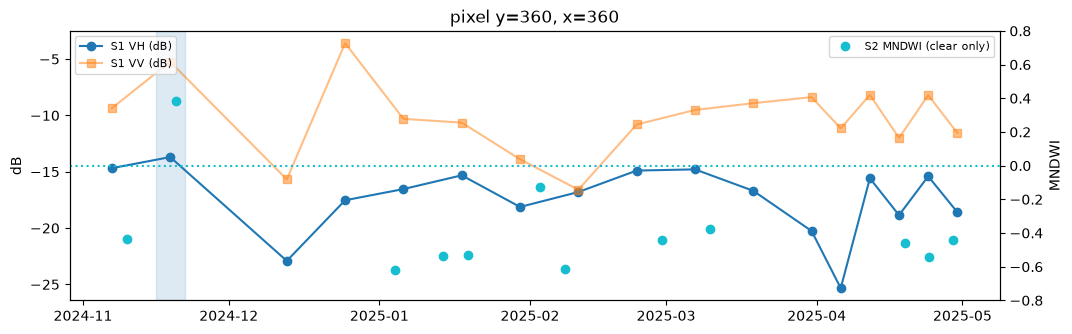

In [5]:
iy, ix = y0 + w // 2, x0 + w // 2
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(s1.time, s1.vh_db[:, iy, ix], "o-", label="S1 VH (dB)")
ax.plot(s1.time, s1.vv_db[:, iy, ix], "s-", alpha=.5, label="S1 VV (dB)")
ax2 = ax.twinx()
mm = m[:, iy, ix]
ax2.plot(s2.time, mm, "o", color="tab:cyan", label="S2 MNDWI (clear only)"); ax2.axhline(0, ls=":", c="tab:cyan")
ax2.set_ylim(-0.8, 0.8); ax2.set_ylabel("MNDWI")
for t, l in zip(s1.time.values, labels[:, iy, ix].values):
    if l == 1: ax.axvspan(t - np.timedelta64(3, "D"), t + np.timedelta64(3, "D"), color="tab:blue", alpha=.15)
ax.set_ylabel("dB"); ax.legend(loc="upper left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
ax.set_title(f"pixel y={iy}, x={ix}")

## 5. From water status to AWD
The model predicts 0/1 for each radar date. A **drying event** is a 1 → 0 transition. Continuous flooding gives about 1 event (final drainage before harvest); AWD gives 2 or more.

Limit to keep in mind: radar revisits every 6-12 days, while an AWD dry phase lasts about 5-10 days. Some dry phases fall between two passes and are missed, which is why field IoT water sensors are a useful complement.

predicted water status for this pixel: -110000000111000-
drying events: 2


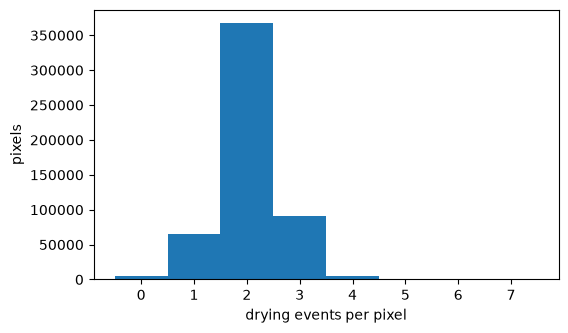

In [6]:
from pathlib import Path
p = Path(cfg["paths"]["outputs"]) / cfg.get("run_name", "real") / "predictions.zarr"
if p.exists():
    pred = xr.open_zarr(p).load()
    seq = pred.water[:, iy, ix].values
    print("predicted water status for this pixel:", "".join("-" if np.isnan(v) else str(int(v)) for v in seq))
    print("drying events:", int(pred.drying_events[iy, ix]))
    fig, ax = plt.subplots(figsize=(6, 3.5))
    vals = pred.drying_events.where(np.isfinite(pred.water).any("time")).values.ravel()
    ax.hist(vals[np.isfinite(vals)], bins=np.arange(-0.5, 8.5, 1)); ax.set_xlabel("drying events per pixel"); ax.set_ylabel("pixels")
else:
    print("run scripts/03_baseline.py first")

## 6. Which fields look like AWD?
Within one crop, **continuous flooding** looks like `0 0 1 1 1 1 1 1 0 0` (flooded at sowing, drained once before harvest), while **AWD** looks like `0 0 1 1 0 1 1 0 1 1 0`: the field dries *and is flooded again*. So we count dry spells followed by re-flooding inside the crop window (`awd.crop_start` / `awd.crop_end` in the config), not all drainages.

0 = continuous flooding, 1 = a single mid-season drainage (common in Vietnam), 2+ = AWD-like. Single-date errors of the classifier can create false dry spells, so treat isolated pixels with caution and look at whole fields.

In [8]:
from matplotlib.colors import ListedColormap
from ricepaddy.awd import PRACTICES
if p.exists() and "practice" in pred:
    colors = ["#9ecae1", "#fdae6b", "#31a354"]
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    im = axs[0].imshow(pred.practice, cmap=ListedColormap(colors), vmin=-0.5, vmax=2.5, interpolation="nearest")
    cb = fig.colorbar(im, ax=axs[0], ticks=[0, 1, 2]); cb.ax.set_yticklabels([PRACTICES[k] for k in range(3)])
    axs[0].set_title("Irrigation practice over the crop window")
    rng = np.random.default_rng(0)
    for k, col in enumerate(colors):
        ys, xs = np.nonzero(pred.practice.values == k)
        if len(ys) == 0: continue
        i = rng.integers(len(ys))
        axs[1].plot(s1.time, s1.vh_db[:, ys[i], xs[i]], "o-", color=col, label=f"{PRACTICES[k]} (y={ys[i]}, x={xs[i]})")
        print(PRACTICES[k], "->", "".join("-" if np.isnan(v) else str(int(v)) for v in pred.water[:, ys[i], xs[i]].values))
    for t in [cfg["awd"]["crop_start"], cfg["awd"]["crop_end"]]:
        axs[1].axvline(pd.Timestamp(t), ls="--", c="k", lw=1)
    axs[1].set_ylabel("VH (dB)"); axs[1].legend(fontsize=7); axs[1].set_title("One random pixel per class (dashed = crop window)")
    shares = pred.practice.to_series().value_counts(normalize=True).sort_index()
    print({PRACTICES[int(k)]: f"{v:.0%}" for k, v in shares.items()})
else:
    print("run scripts/03_baseline.py (with the same config) first")

run scripts/03_baseline.py (with the same config) first
